Cavity geometry
----------------
Base period a      = 201000000.00 nm
Central spacing a0 = 175000000.00 nm
Central gap d      = 59000000.00 nm
Fixed radius       = 58000000.00 nm
Sigma              = 3.960
Holes per side     = 25
Total holes        = 50

Selected spacings
-----------------
a_0 = 175000000.000 nm
a_1 = 175815920.313 nm
a_2 = 178113241.046 nm
a_3 = 181485924.537 nm
a_4 = 185389488.324 nm
a_5 = 189283665.275 nm
a_6 = 192749659.427 nm
a_7 = 195549235.029 nm

Source
------
Center frequency = 513.930 THz
Bandwidth        = 85.655 THz
Target frequency = 483.536 THz

Simulation
----------
Size = 11507917.553 x 1869000.000 x 1802000.000 um
Runtime    = 3.000 ps
Mode start = 2.987591 ps
Mode stop  = 3.000000 ps
Symmetry   = (1, -1, 0)
Shutoff    = 0.0


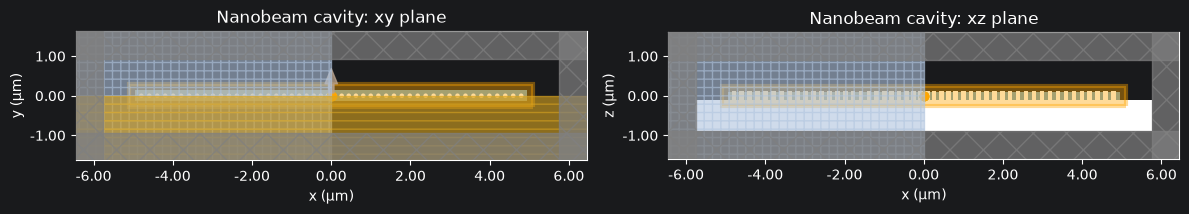

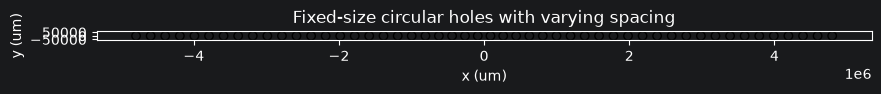

In [52]:
# ============================================================
# Low-credit exponentially spaced 1D PhC nanobeam cavity
#
# Calculates:
#   - approximate resonance wavelength
#   - approximate Q-factor
#   - approximate mode volume
#
# All lengths are in meters.
#
# Hole radii are fixed.
# Only the hole spacing changes according to:
#
#   a_j = a - (a-a0) * exp[-j^2/(2*sigma^2)]
#
# where:
#
#   a0 = d + 2*r
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

import tidy3d as td
from tidy3d import web
from tidy3d.plugins.resonance import ResonanceFinder


# ============================================================
# 1. Parameters
# ============================================================

# Nanobeam dimensions
height = 0.202                  # 202 nm
width = 0.269                  # 269 nm
lattice_constant = 0.201      # 201 nm

# Fixed circular hole radius
radius = 0.058                 # 58 nm

# Central dielectric gap and taper parameter
d = 0.059                      # 59 nm
sigma = 3.96

# Reduced number of holes for lower computational cost
n_holes_each_side = 25

# Source bandwidth
wl1 = 0.50                     # 500 nm
wl2 = 0.70                      # 700 nm

# Target cavity wavelength
target_wavelength = 0.620      # 620 nm
target_frequency = td.C_0 / target_wavelength

# Material indices
waveguide_index = 2.40
substrate_index = 1
background_index = 1.0

polarization = "Ey"

# Shorter runtime for an approximate Q-factor
run_time = 3e-12                 # 1.5 ps

# Coarse mesh
delta_override = 0.005             # 10 nm
min_steps_per_wvl = 10

# Reduced transverse padding.
padding_xy = 0.8
padding_z = 0.8

# Number of target-wavelength periods stored for mode volume
n_mode_volume_periods = 6

# Disable early shutoff so the final mode-volume monitor is populated.
shutoff = 0.0

# The symmetric cavity uses x-even and y-odd symmetry for Ey.
# z symmetry is disabled because of the substrate.
use_symmetry = True

# First inspect geometry with False.
RUN_SIMULATION = False


# ============================================================
# 2. Exponential hole spacing
# ============================================================

def exponential_spacing(
    j,
    lattice_constant,
    radius,
    d,
    sigma,
):
    """
    Center-to-center hole spacing:

        a_j = a - (a-a0) exp[-j^2/(2*sigma^2)]

    where:

        a0 = d + 2*r

    The hole radius is constant for every hole.
    """

    a0 = d + 2 * radius

    return (
        lattice_constant
        - (lattice_constant - a0)
        * np.exp(-j**2 / (2 * sigma**2))
    )


def make_hole_positions(
    lattice_constant,
    radius,
    d,
    sigma,
    n_holes_each_side,
):
    """
    Generate symmetric hole-center positions.

    The two central holes have center-to-center spacing:

        a0 = d + 2*r

    so the central dielectric gap is d.
    """

    if n_holes_each_side < 1:
        raise ValueError(
            "n_holes_each_side must be at least 1."
        )

    a0 = d + 2 * radius

    # Right-side hole positions
    x_right = np.zeros(n_holes_each_side)

    # Position of the innermost right hole
    x_right[0] = a0 / 2

    # Move outward from the cavity center
    for hole_index in range(1, n_holes_each_side):

        spacing = exponential_spacing(
            j=hole_index,
            lattice_constant=lattice_constant,
            radius=radius,
            d=d,
            sigma=sigma,
        )

        x_right[hole_index] = (
            x_right[hole_index - 1] + spacing
        )

    # Mirror the right side to make the left side
    x_left = -x_right[::-1]

    return np.concatenate(
        [
            x_left,
            x_right,
        ]
    )


x_holes = make_hole_positions(
    lattice_constant=lattice_constant,
    radius=radius,
    d=d,
    sigma=sigma,
    n_holes_each_side=n_holes_each_side,
)

a0 = d + 2 * radius

print("Cavity geometry")
print("----------------")
print(f"Base period a      = {lattice_constant * 1e9:.2f} nm")
print(f"Central spacing a0 = {a0 * 1e9:.2f} nm")
print(f"Central gap d      = {d * 1e9:.2f} nm")
print(f"Fixed radius       = {radius * 1e9:.2f} nm")
print(f"Sigma              = {sigma:.3f}")
print(f"Holes per side     = {n_holes_each_side}")
print(f"Total holes        = {len(x_holes)}")

print("\nSelected spacings")
print("-----------------")

for j in range(min(8, n_holes_each_side)):

    spacing = exponential_spacing(
        j=j,
        lattice_constant=lattice_constant,
        radius=radius,
        d=d,
        sigma=sigma,
    )

    print(
        f"a_{j} = {spacing * 1e9:.3f} nm"
    )


# ============================================================
# 3. Materials
# ============================================================

air = td.Medium(
    permittivity=background_index**2
)

waveguide = td.Medium(
    permittivity=waveguide_index**2
)

substrate_medium = td.Medium(
    permittivity=substrate_index**2
)


# ============================================================
# 4. Geometry using td.Cylinder
# ============================================================

# Add dielectric beyond the outermost holes.
beam_edge_margin = 0.5 * lattice_constant

beam_length = 2 * (
    abs(x_holes[-1])
    + radius
    + beam_edge_margin
)



simulation_size = (
    beam_length + 2 * padding_xy,
    width + 2 * padding_xy,
    height + 2 * padding_z,
)

# Dielectric nanobeam
beam_structure = td.Structure(
    geometry=td.Box(
        center=(0, 0, 0),
        size=(
            beam_length,
            width,
            height,
        ),
    ),
    medium=waveguide,
    name="nanobeam",
)

# Fixed-size circular air holes.
# The radius is identical for every hole.
hole_structures = []

for hole_index, x_position in enumerate(x_holes):

    hole_geometry = td.Cylinder(
        center=(x_position, 0, 0),
        radius=radius,
        length=height + 0.02,
        axis=2,
    )

    hole_structures.append(
        td.Structure(
            geometry=hole_geometry,
            medium=air,
            name=f"hole_{hole_index}",
        )
    )

# Substrate below the beam
substrate_structure = td.Structure(
    geometry=td.Box.from_bounds(
        rmin=(
            -simulation_size[0] / 2,
            -simulation_size[1] / 2,
            -simulation_size[2] / 2,
        ),
        rmax=(
            simulation_size[0] / 2,
            simulation_size[1] / 2,
            -height / 2,
        ),
    ),
    medium=substrate_medium,
    name="substrate",
)

# Later structures override earlier structures.
structures = [
    substrate_structure,
    beam_structure,
] + hole_structures


# ============================================================
# 5. Source
# ============================================================

freq1 = td.C_0 / wl1
freq2 = td.C_0 / wl2

freq0 = 0.5 * (freq1 + freq2)
fwidth = 0.5 * abs(freq1 - freq2)

source = td.PointDipole(
    center=(0, 0, 0),
    polarization=polarization,
    source_time=td.GaussianPulse(
        freq0=freq0,
        fwidth=fwidth,
        phase=0,
    ),
    name="cavity_source",
)

print("\nSource")
print("------")
print(f"Center frequency = {freq0 / 1e12:.3f} THz")
print(f"Bandwidth        = {fwidth / 1e12:.3f} THz")
print(
    f"Target frequency = "
    f"{target_frequency / 1e12:.3f} THz"
)


# ============================================================
# 6. Monitors
# ============================================================

# A small number of point monitors reduces stored data.
point_positions = [
    (0.00 * lattice_constant, 0, 0),
    (0.08 * lattice_constant, 0, 0),
]

point_monitors = []

for monitor_index, position in enumerate(point_positions):

    point_monitors.append(
        td.FieldTimeMonitor(
            center=position,
            size=(0, 0, 0),
            fields=["Ey"],
            start=0,
            stop=run_time,
            interval=1,
            name=f"pointMon{monitor_index}",
        )
    )


# Mode-volume monitor records only the end of the simulation.
target_period = target_wavelength / td.C_0

mode_start = (
    run_time
    - n_mode_volume_periods * target_period
)

mode_stop = run_time

if mode_start <= 0:
    raise ValueError(
        "Mode-volume monitor starts before t=0. "
        "Increase run_time."
    )

# Do not monitor the PML region.
# This smaller box reduces monitor storage.
mode_monitor_size = (
    beam_length + 0.30,
    width + 0.30,
    height + 0.30,
)

# Only Ey is recorded because this is an Ey-dominated mode.
mode_volume_monitor = td.FieldTimeMonitor(
    center=(0, 0, 0),
    size=mode_monitor_size,
    fields=["Ey"],
    start=mode_start,
    stop=mode_stop,
    interval=4,
    interval_space=(4, 4, 4),
    name="modeVolumeMon",
)

monitors = point_monitors + [
    mode_volume_monitor,
]


# ============================================================
# 7. Mesh and simulation
# ============================================================

mesh_override = td.MeshOverrideStructure(
    geometry=td.Box(
        center=(0, 0, 0),
        size=(
            beam_length,
            width,
            height,
        ),
    ),
    dl=(
        delta_override,
        delta_override,
        delta_override,
    ),
)

grid_spec = td.GridSpec.auto(
    min_steps_per_wvl=min_steps_per_wvl,
    override_structures=[mesh_override],
)

boundary_spec = td.BoundarySpec(
    x=td.Boundary.pml(),
    y=td.Boundary.pml(),
    z=td.Boundary.pml(),
)

if use_symmetry:
    # Ey-like mode:
    # x: even
    # y: odd
    # z: no symmetry because of substrate
    symmetry = (1, -1, 0)
else:
    symmetry = (0, 0, 0)

sim = td.Simulation(
    center=(0, 0, 0),
    size=simulation_size,
    medium=air,
    structures=structures,
    sources=[source],
    monitors=monitors,
    boundary_spec=boundary_spec,
    grid_spec=grid_spec,
    run_time=run_time,
    shutoff=shutoff,
    symmetry=symmetry,
    courant=0.99,
)


# ============================================================
# 8. Local validation
# ============================================================

print("\nSimulation")
print("----------")
print(
    f"Size = "
    f"{simulation_size[0] * 1e6:.3f} x "
    f"{simulation_size[1] * 1e6:.3f} x "
    f"{simulation_size[2] * 1e6:.3f} um"
)
print(f"Runtime    = {run_time * 1e12:.3f} ps")
print(f"Mode start = {mode_start * 1e12:.6f} ps")
print(f"Mode stop  = {mode_stop * 1e12:.6f} ps")
print(f"Symmetry   = {symmetry}")
print(f"Shutoff    = {shutoff}")

assert 0 <= mode_start < mode_stop <= sim.run_time

sim.validate_pre_upload()

# Plot the geometry.
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
)

sim.plot(
    z=0,
    ax=axes[0],
)

axes[0].set_title("Nanobeam cavity: xy plane")

sim.plot(
    y=0,
    ax=axes[1],
)

axes[1].set_title("Nanobeam cavity: xz plane")

plt.tight_layout()
plt.show()


# Plot hole centers to verify that hole sizes are fixed.
fig, ax = plt.subplots(figsize=(10, 3))

for x_position in x_holes:

    circle = plt.Circle(
        (
            x_position * 1e6,
            0,
        ),
        radius * 1e6,
        fill=False,
        color="black",
    )

    ax.add_patch(circle)

ax.set_aspect("equal")
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")
ax.set_title(
    "Fixed-size circular holes with varying spacing"
)
ax.autoscale()
plt.show()


In [53]:
# estimating the cost
RUN_SIMULATION = True
task_id = web.upload(sim, "nanobeam_test")
cost = web.estimate_cost(task_id)

17:09:52 EDT Created task 'nanobeam_test' with resource_id                      
             'fdve-2d1e8db4-455c-4766-aec1-02cb94f83689' and task_type 'FDTD'.

             View task using web UI at                                          
             ]8;id=1314947;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d1e8db4-455c-4766-aec1-02cb94f83689\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=1314948;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d1e8db4-455c-4766-aec1-02cb94f83689\taskId]8;;\]8;id=1314947;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d1e8db4-455c-4766-aec1-02cb94f83689\=]8;;\]8;id=1314949;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d1e8db4-455c-4766-aec1-02cb94f83689\fdve]8;;\]8;id=1314947;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d1e8db4-455c-4766-aec1-02cb94f83689\-2d1e8db4-455]8;;\
             ]8;id=1314947;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d1e8db4-455c-4766-aec1-02cb94f83689\c-4766-aec1-02cb94f83689']8;;\.

             Task folder: ]8;id=1314951;https://tidy3d.simulation.cloud/folders/folder-a7dd507c-3997-4acc-a56e-79b7a3e3748b\'default']8;;\.

/Users/sarahshan/Documents/photonic-simulations/Photonics/.venv/lib/python3.11/s
ite-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter 
support
  warnings.warn('install "ipywidgets" for Jupyter support')

17:09:53 EDT Estimated FlexCredit cost: 0.670. This assumes the FDTD solver runs
             for the full simulation time; if early shutoff is reached, the     
             billed cost can be lower. Use 'web.real_cost(task_id)' to get the  
             billed FlexCredit cost after a simulation run.

17:09:54 EDT Estimated FlexCredit cost: 0.670. This assumes the FDTD solver runs
             for the full simulation time; if early shutoff is reached, the     
             billed cost can be lower. Use 'web.real_cost(task_id)' to get the  
             billed FlexCredit cost after a simulation run.

In [54]:
# ============================================================
# 9. Run the simulation
# ============================================================


sim_data = web.run(
    simulation=sim,
    task_name="exponential_fixed_hole_nanobeam",
)

17:10:04 EDT Created task 'exponential_fixed_hole_nanobeam' with resource_id    
             'fdve-28caed44-5742-4a4a-aa4e-194e16370905' and task_type 'FDTD'.

             View task using web UI at                                          
             ]8;id=1314955;https://tidy3d.simulation.cloud/workbench?taskId=fdve-28caed44-5742-4a4a-aa4e-194e16370905\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=1314956;https://tidy3d.simulation.cloud/workbench?taskId=fdve-28caed44-5742-4a4a-aa4e-194e16370905\taskId]8;;\]8;id=1314955;https://tidy3d.simulation.cloud/workbench?taskId=fdve-28caed44-5742-4a4a-aa4e-194e16370905\=]8;;\]8;id=1314957;https://tidy3d.simulation.cloud/workbench?taskId=fdve-28caed44-5742-4a4a-aa4e-194e16370905\fdve]8;;\]8;id=1314955;https://tidy3d.simulation.cloud/workbench?taskId=fdve-28caed44-5742-4a4a-aa4e-194e16370905\-28caed44-574]8;;\
             ]8;id=1314955;https://tidy3d.simulation.cloud/workbench?taskId=fdve-28caed44-5742-4a4a-aa4e-194e16370905\2-4a4a-aa4e-194e16370905']8;;\.

             Task folder: ]8;id=1314959;https://tidy3d.simulation.cloud/folders/folder-a7dd507c-3997-4acc-a56e-79b7a3e3748b\'default']8;;\.

17:10:06 EDT Estimated FlexCredit cost: 0.670. This assumes the FDTD solver runs
             for the full simulation time; if early shutoff is reached, the     
             billed cost can be lower. Use 'web.real_cost(task_id)' to get the  
             billed FlexCredit cost after a simulation run.

17:10:07 EDT status = queued

             To cancel the simulation, use 'web.abort(task_id)' or              
             'web.delete(task_id)' or abort/delete the task in the web UI.      
             Terminating the Python script will not stop the job running on the 
             cloud.

... (3 outputs left out)

17:18:31 EDT status = success

17:18:33 EDT View simulation result at                                          
             ]8;id=1314962;https://tidy3d.simulation.cloud/workbench?taskId=fdve-28caed44-5742-4a4a-aa4e-194e16370905\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=1314963;https://tidy3d.simulation.cloud/workbench?taskId=fdve-28caed44-5742-4a4a-aa4e-194e16370905\taskId]8;;\]8;id=1314962;https://tidy3d.simulation.cloud/workbench?taskId=fdve-28caed44-5742-4a4a-aa4e-194e16370905\=]8;;\]8;id=1314964;https://tidy3d.simulation.cloud/workbench?taskId=fdve-28caed44-5742-4a4a-aa4e-194e16370905\fdve]8;;\]8;id=1314962;https://tidy3d.simulation.cloud/workbench?taskId=fdve-28caed44-5742-4a4a-aa4e-194e16370905\-28caed44-574]8;;\
             ]8;id=1314962;https://tidy3d.simulation.cloud/workbench?taskId=fdve-28caed44-5742-4a4a-aa4e-194e16370905\2-4a4a-aa4e-194e16370905']8;;\.

17:18:37 EDT Loading results from simulation_data.hdf5

17:18:38 EDT WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       


Resonance result
----------------
Frequency  = 485.278865 THz
Wavelength = 617.773573 nm
Q-factor   = 6.332994e+06
Available resonance columns:
['decay', 'Q', 'amplitude', 'phase', 'error', 'frequency_Hz', 'wavelength_um', 'wavelength_nm', 'Q_abs']

Candidate resonances
--------------------
              frequency_Hz  wavelength_nm             Q         Q_abs
freq                                                                 
4.852789e+14  4.852789e+14     617.773573  6.332994e+06  6.332994e+06


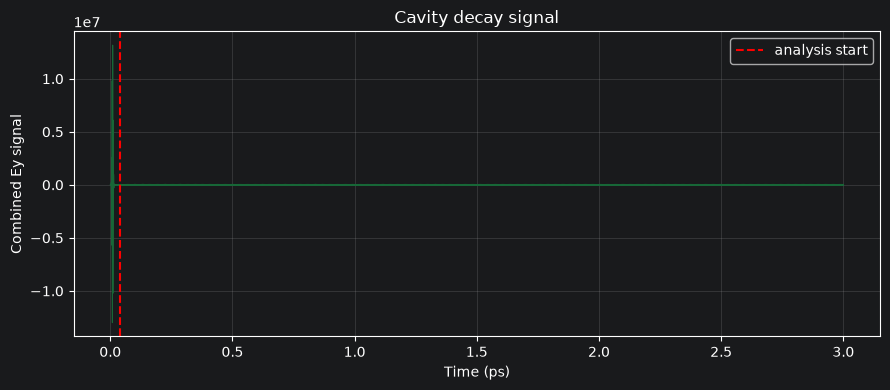


Mode-volume result
------------------
V_eff = 6.984339e-03 um^3
V_eff / (lambda/n)^3 = 0.409516


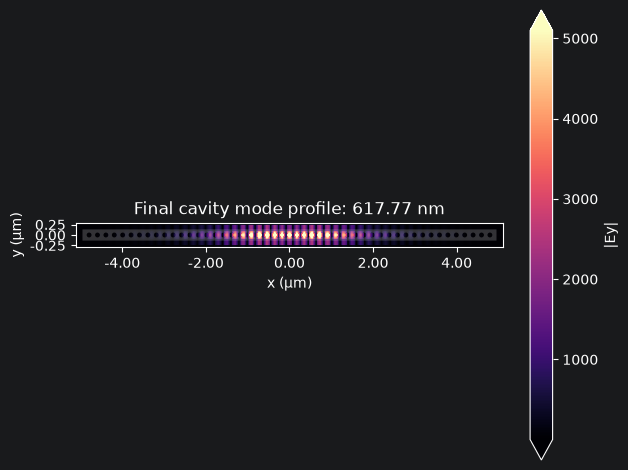

In [55]:
# ============================================================
# 10. Resonance and Q-factor analysis
# ============================================================

from tidy3d.plugins.resonance import ResonanceFinder


def find_source_decay(source):
    """
    Estimate when the Gaussian source has decayed.
    """

    source_fwidth = float(
        source.source_time.fwidth
    )

    source_offset = float(
        source.source_time.offset
    )

    offset_time = (
        source_offset
        / (2 * np.pi * source_fwidth)
    )

    pulse_time = 0.44 / source_fwidth

    return offset_time + pulse_time


def combine_point_monitor_signals(
    sim_data,
    number_of_monitors,
    polarization="Ey",
):
    """
    Sum the point-monitor signals.

    Combining several monitors reduces the chance that the
    selected resonance is located at a field node of one
    particular monitor.
    """

    signals = []

    for monitor_index in range(number_of_monitors):

        monitor_name = f"pointMon{monitor_index}"

        monitor_data = sim_data[monitor_name]

        field_signal = getattr(
            monitor_data,
            polarization,
        ).squeeze()

        signals.append(field_signal)

    combined_signal = signals[0]

    for signal in signals[1:]:
        combined_signal = (
            combined_signal + signal
        )

    return combined_signal


combined_signal = combine_point_monitor_signals(
    sim_data=sim_data,
    number_of_monitors=len(point_positions),
    polarization=polarization,
)

time_values = np.asarray(
    combined_signal.coords["t"].values,
    dtype=float,
)

source_decay_time = find_source_decay(source)

# Analyze only after the source has substantially decayed.
analysis_start = max(
    2 * source_decay_time,
    20 * target_period,
)

time_mask = time_values >= analysis_start
time_indices = np.where(time_mask)[0]

if len(time_indices) < 100:
    raise RuntimeError(
        "Too few samples remain after source decay. "
        "Increase run_time or reduce analysis_start."
    )

signal_after_source = combined_signal.isel(
    t=time_indices
)

freq_window = (
    freq0 - fwidth / 2,
    freq0 + fwidth / 2,
)

resonance_finder = ResonanceFinder(
    freq_window=freq_window
)

resonance_data = resonance_finder.run_raw_signal(
    signal_after_source,
    sim_data.simulation.dt,
)

resonance_df = resonance_data.to_dataframe()

if resonance_df.empty:
    raise RuntimeError(
        "ResonanceFinder found no resonances. "
        "Try increasing run_time or widening freq_window."
    )

# ResonanceFinder stores the resonance frequencies in the
# dataframe index.
resonance_frequencies = np.asarray(
    resonance_df.index,
    dtype=float,
)

resonance_df["frequency_Hz"] = (
    resonance_frequencies
)

resonance_df["wavelength_um"] = (
    td.C_0
    / resonance_df["frequency_Hz"]
)

resonance_df["wavelength_nm"] = (
    1000.0
    * resonance_df["wavelength_um"]
)

resonance_df["Q_abs"] = np.abs(
    resonance_df["Q"]
)

valid_resonances = (
    np.isfinite(
        resonance_df["frequency_Hz"]
    )
    & np.isfinite(
        resonance_df["wavelength_nm"]
    )
    & np.isfinite(
        resonance_df["Q_abs"]
    )
    & (resonance_df["Q_abs"] > 0)
)

resonance_df = resonance_df.loc[
    valid_resonances
].copy()

if resonance_df.empty:
    raise RuntimeError(
        "No valid positive-Q resonances were found."
    )

# Select the resonance nearest to the target wavelength.
nearest_resonance_index = np.argmin(
    np.abs(
        resonance_df["wavelength_um"].values
        - target_wavelength
    )
)

selected_resonance = resonance_df.iloc[
    nearest_resonance_index
]

resonant_frequency = float(
    selected_resonance["frequency_Hz"]
)

resonant_wavelength_um = float(
    selected_resonance["wavelength_um"]
)

resonant_wavelength_nm = float(
    selected_resonance["wavelength_nm"]
)

Q_factor = float(
    selected_resonance["Q_abs"]
)

print("\nResonance result")
print("----------------")
print(
    f"Frequency  = "
    f"{resonant_frequency / 1e12:.6f} THz"
)
print(
    f"Wavelength = "
    f"{resonant_wavelength_nm:.6f} nm"
)
print(
    f"Q-factor   = "
    f"{Q_factor:.6e}"
)

print("Available resonance columns:")
print(resonance_df.columns.tolist())

required_columns = [
    "frequency_Hz",
    "wavelength_nm",
    "Q",
    "Q_abs",
]

missing_columns = [
    column
    for column in required_columns
    if column not in resonance_df.columns
]

if missing_columns:
    raise RuntimeError(
        f"Missing resonance columns: {missing_columns}"
    )

print("\nCandidate resonances")
print("--------------------")

print(
    resonance_df
    .sort_values("Q_abs", ascending=False)
    [required_columns]
    .head(10)
)


# Plot the combined temporal signal.
plt.figure(figsize=(9, 4))

plt.plot(
    time_values * 1e12,
    np.real(
        np.asarray(
            combined_signal.values
        )
    ),
    linewidth=0.8,
)

plt.axvline(
    analysis_start * 1e12,
    color="red",
    linestyle="--",
    label="analysis start",
)

plt.xlabel("Time (ps)")
plt.ylabel("Combined Ey signal")
plt.title("Cavity decay signal")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 11. Mode-volume calculation
# ============================================================

def calculate_mode_volume(
    sim,
    sim_data,
    resonant_wavelength_um,
    waveguide_index,
    monitor_name="modeVolumeMon",
):
    """
    Calculate:

        V_eff =
        integral[eps(r) |E(r)|^2 dV]
        /
        max[eps(r) |E(r)|^2]

    using the temporal average of the field recorded during
    the final two optical periods.

    Returns:
        V_eff_um3
        V_eff_normalized
        energy_density
        epsilon_on_monitor_grid
    """

    field_data = sim_data[monitor_name]

    Ex = field_data.Ex
    Ey = field_data.Ey
    Ez = field_data.Ez

    if "t" not in Ey.coords:
        raise RuntimeError(
            "The mode-volume monitor does not contain a "
            "time coordinate."
        )

    t_values = np.asarray(
        Ey.coords["t"].values,
        dtype=float,
    )

    if len(t_values) < 2:
        raise RuntimeError(
            "The mode-volume monitor contains fewer than "
            "two time samples."
        )

    # Obtain relative permittivity on a spatial grid.
    epsilon = sim.epsilon(
        box=td.Box(
            center=(0, 0, 0),
            size=sim.size,
        )
    )

    epsilon = np.real(epsilon)

    # Interpolate epsilon to the electric-field monitor grid.
    epsilon_monitor = epsilon.interp(
        coords={
            "x": Ey.coords["x"],
            "y": Ey.coords["y"],
            "z": Ey.coords["z"],
        }
    )

    # Electric energy-density-like quantity.
    # The field normalization cancels in V_eff.
    energy_density_time = (
        epsilon_monitor
        * (
            + np.abs(Ey) ** 2
        )
    )

    # Temporal average over the recorded final field cycles.
    time_duration = (
        t_values[-1] - t_values[0]
    )

    energy_density = (
        energy_density_time.integrate(
            coord="t"
        )
        / time_duration
    )

    # Integrate over the full spatial monitor volume.
    integrated_energy = (
        energy_density.integrate(
            coord=("x", "y", "z")
        )
    )

    maximum_energy_density = (
        energy_density.max()
    )

    V_eff = (
        integrated_energy
        / maximum_energy_density
    )

    V_eff_um3 = float(
        np.real(
            V_eff.values
        )
    )

    # Normalize using (lambda/n)^3.
    normalization_volume = (
        resonant_wavelength_um
        / waveguide_index
    ) ** 3

    V_eff_normalized = (
        V_eff_um3
        / normalization_volume
    )

    return (
        V_eff_um3,
        V_eff_normalized,
        energy_density,
        epsilon_monitor,
    )


(
    V_eff_um3,
    V_eff_normalized,
    energy_density,
    epsilon_on_grid,
) = calculate_mode_volume(
    sim=sim,
    sim_data=sim_data,
    resonant_wavelength_um=resonant_wavelength_um,
    waveguide_index=waveguide_index,
    monitor_name="modeVolumeMon",
)

print("\nMode-volume result")
print("------------------")
print(
    f"V_eff = "
    f"{V_eff_um3:.6e} um^3"
)
print(
    f"V_eff / (lambda/n)^3 = "
    f"{V_eff_normalized:.6f}"
)


# ============================================================
# 12. Plot the final cavity mode profile
# ============================================================

profile_data = sim_data[
    "modeVolumeMon"
].Ey

profile_times = np.asarray(
    profile_data.coords["t"].values,
    dtype=float,
)

if len(profile_times) > 0:

    sim_data.plot_field(
        "modeVolumeMon",
        "Ey",
        val="abs",
        z=0,
        t=float(profile_times[-1]),
    )

    plt.title(
        "Final cavity mode profile: "
        f"{resonant_wavelength_nm:.2f} nm"
    )

    plt.show()
else:
    print(
        "modeVolumeMon contains no time samples. "
        "Check profile_start, profile_stop, and shutoff."
    )

In [41]:
purcell = 3/4/(3.14)**2*Q_factor/V_eff_normalized
print(purcell)

1188133.6732047678
